# Replicating the DFTHC resource estimates of Low et al. (PRX 2025)

This notebook uses the `dfthc` package in this repository to reproduce the resource estimates of

> G. H. Low *et al.*, *Fast quantum simulation of electronic structure by spectrum amplification*,
> [PRX **15**, 041016 (2025)](https://journals.aps.org/prx/abstract/10.1103/pb2g-j9cw),
> [arXiv:2502.15882](https://arxiv.org/abs/2502.15882).

The paper builds a block encoding of the electronic-structure Hamiltonian from a double-factorized
tensor hypercontraction (DFTHC) and costs its qubitized walk gate by gate (its Table III, and App. B).
Here every block is a PennyLane operator that compiles, with `qp.qjit(capture=True)` and graph-based
`qp.decompose`, down to Cliffords, `TemporaryAND`, measured AND-uncomputes and mid-circuit
measurements. `qp.analyze` then counts the compiled program exactly. The Qualtran implementation
[dfthcbe](https://github.com/Covestro-HPQC/dfthcbe) is a second point of comparison.

What the notebook reproduces:

1. **Toffolis per walk step** for H$_2$, naphthalene, Fe$_2$S$_2$, Fe$_4$S$_4$ and FeMoco-54: compiled
   and counted, checked against the closed forms in `dfthc.costs`, and set beside the paper's and
   dfthcbe's numbers.
2. **The block-by-block breakdown at FeMoco-54** (the paper's Table III: 9,997 Toffolis per step).
3. **Logical qubits at FeMoco-54** (the paper's 1,131).
4. **Phase-estimation cost**, built from the controlled walk.
5. **Correctness**: the compiled block encoding of H$_2$, simulated, equals the encoded Hamiltonian.

**Running it.** Create the environment with `scripts/setup_env.sh` (Python 3.12, nightly PennyLane
and Catalyst; see `docs/environment.md`), add Jupyter to it (`.venv/bin/pip install ipykernel`), and
start the notebook from anywhere inside the repository. Compiles print a benign
`ld: warning: object file ... was built for newer 'macOS' version` on macOS. With the default settings it runs in a few
minutes. Set `COMPILE_LARGE = True` below to also compile the three large systems (about 1 minute
and up to 2 GB each).

In [1]:
import sys
import time
import warnings
from pathlib import Path

# Find the repository root and put src/ on the path (dfthc is not installed as a package).
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "dfthc").is_dir())
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pennylane as qp
from IPython.display import Markdown, display

import dfthc
from dfthc import costs, costs_reference
from dfthc.compile import compiled_resources
from dfthc.data.factors import load_factors, random_factors
from dfthc.ops.walk import DFTHCWalk
from dfthc.params import FEMOCO54
from dfthc.registers import WalkLayout
from dfthc.testing.resources import UNRESOLVED_BRANCH_MESSAGE

# qp.analyze warns that it cannot resolve a conditional's branch; the counts are still exact.
warnings.filterwarnings("ignore", message=UNRESOLVED_BRANCH_MESSAGE, category=UserWarning)

COMPILE_LARGE = False  # True also compiles Fe2S2, Fe4S4 and FeMoco-54 (about 1 min, <2 GB each)

print("pennylane", qp.__version__, "| catalyst", __import__("catalyst").__version__)

pennylane 0.46.0-dev151 | catalyst 0.16.0-dev140


In [2]:
def table(header, rows):
    # Render rows as a Markdown table; numbers get thousands separators.
    fmt = lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else str(v)
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. A first compile: the README quick start

A walk at small test precisions on H$_2$/STO-3G. The gate set has no `Toffoli`: every Toffoli is a
`TemporaryAND`, uncomputed later by a measurement (`Adjoint(TemporaryAND)`).

In [3]:
params = dfthc.H2_STO3G_TEST
tables = dfthc.WalkTables.from_factors(load_factors("h2_sto3g_R2_B2_C1"), params)
wires = qp.registers(dfthc.DFTHCWalk.required_wires(params))
num_wires = sum(len(w) for w in wires.values())

@qp.qjit(capture=True)
@qp.decompose(gate_set=dfthc.GATE_SET)
@qp.qnode(qp.device("null.qubit", wires=num_wires))
def walk():
    qp.PhaseGradientStatePrep(wires["phase_grad"])
    dfthc.DFTHCWalk(params, tables, **wires)
    return qp.probs(wires=0)

counts = qp.analyze(walk)().resources.counts
print("gate set:", sorted(dfthc.GATE_SET))
print("TemporaryAND (Toffolis):          ", counts["TemporaryAND"])
print("Adjoint(TemporaryAND) (measured): ", counts["Adjoint(TemporaryAND)"])
print("closed form (dfthc.costs.walk):   ", costs.walk(params, controlled=False))

gate set: ['Adjoint(S)', 'Adjoint(TemporaryAND)', 'CNOT', 'CZ', 'GlobalPhase', 'Hadamard', 'MidMeasure', 'PauliX', 'PauliY', 'PauliZ', 'PhaseGradientStatePrep', 'S', 'SWAP', 'TemporaryAND']
TemporaryAND (Toffolis):           158
Adjoint(TemporaryAND) (measured):  158
closed form (dfthc.costs.walk):    Cost(toffoli=158, measurements=48)


## 2. The systems

The DFTHC factors of H$_2$, naphthalene, Fe$_2$S$_2$ and Fe$_4$S$_4$ are vendored from dfthcbe under
`data/dfthc/`. Each system gets the paper's precisions (Table III: $b_\mathrm{rot} = b_{k_1} = b_{k_2} = 15$,
$s_u = 7$) and the QROAM block bits $(k_1, k_2, k_{e_1}, k_{e_2})$ that minimize the walk's Toffolis
(`costs_reference.default_params`).

The FeMoco-54 factors are not public, so FeMoco-54 uses random factors of the paper's shape
($N = 54$, $R = 10$, $B = C = 27$) with the paper's block bits (`dfthc.params.FEMOCO54`). The gate counts
depend only on the shape and precisions, never on the factor values, so this costs exactly the
paper's circuit.

In [4]:
SYSTEMS = {  # name: (label, factors loader)
    "h2_sto3g_R2_B2_C1": ("H2, STO-3G", lambda: load_factors("h2_sto3g_R2_B2_C1")),
    "naphthalene": ("naphthalene", lambda: load_factors("naphthalene")),
    "fe2s2": ("Fe2S2", lambda: load_factors("fe2s2")),
    "fe4s4": ("Fe4S4", lambda: load_factors("fe4s4")),
    "femoco54": ("FeMoco-54", lambda: random_factors(54, 10, 27, 27, n_plus=27, seed=0)),
}
LARGE = {"fe2s2", "fe4s4", "femoco54"}

systems = {}
for name, (label, loader) in SYSTEMS.items():
    factors = loader()
    if name == "femoco54":
        p = FEMOCO54
    else:
        p = costs_reference.default_params(factors.N, factors.R, factors.B, factors.C,
                                           factors.n_plus)
    systems[name] = dict(label=label, params=p, tables=dfthc.WalkTables.from_factors(factors, p),
                         layout=WalkLayout.from_params(p))

table(["System", "N", "R", "B", "C", "k1", "k2", "ke1", "ke2", "Walk qubits"],
      [[s["label"], p.N, p.R, p.B, p.C, p.k1, p.k2, p.ke1, p.ke2, s["layout"].num_wires]
       for s in systems.values() for p in [s["params"]]])

| System | N | R | B | C | k1 | k2 | ke1 | ke2 | Walk qubits |
|---|---|---|---|---|---|---|---|---|---|
| H2, STO-3G | 2 | 2 | 2 | 1 | 0 | 0 | 1 | 0 | 177 |
| naphthalene | 10 | 8 | 6 | 5 | 1 | 2 | 3 | 1 | 327 |
| Fe2S2 | 20 | 6 | 29 | 15 | 1 | 3 | 3 | 1 | 498 |
| Fe4S4 | 36 | 33 | 11 | 3 | 1 | 3 | 4 | 1 | 757 |
| FeMoco-54 | 54 | 10 | 27 | 27 | 2 | 4 | 4 | 2 | 1,049 |

## 3. Toffolis per walk step

Three numbers per system:

- **Ours**: `dfthc.costs.walk`, the closed form of our circuit (compiled and checked in Section 4);
- **dfthcbe**: `costs_reference.dfthcbe_blocks`, dfthcbe's per-step formulas at the same parameters;
- **Paper**: `costs_reference.paper_table3`, the paper's Table III and App. B formulas at the same
  parameters. At FeMoco-54 this is the paper's published 9,997.

The paper's 9,997 is the cost of its QPE step, whose control sits on the final reflection only, so
the closest comparison is our controlled walk, also listed.

In [5]:
rows = []
for s in systems.values():
    p = s["params"]
    ours, ours_c = costs.walk(p, False).toffoli, costs.walk(p, True).toffoli
    ref, paper = costs_reference.dfthcbe_blocks(p)["walk"], costs_reference.paper_table3(p)["walk"]
    s.update(ours=ours, dfthcbe=ref, paper=paper)
    rows.append([s["label"], s["layout"].num_wires, ours, ours_c, ref, paper,
                 f"{ours - ref:+,}", f"{ours - paper:+,} ({(ours - paper) / paper:+.1%})"])

table(["System", "Walk qubits", "Ours", "Ours (controlled)", "dfthcbe", "Paper",
       "Ours − dfthcbe", "Ours − paper"], rows)
assert systems["femoco54"]["paper"] == 9997  # the paper's Table III total

| System | Walk qubits | Ours | Ours (controlled) | dfthcbe | Paper | Ours − dfthcbe | Ours − paper |
|---|---|---|---|---|---|---|---|
| H2, STO-3G | 177 | 341 | 343 | 392 | 400 | -51 | -59 (-14.8%) |
| naphthalene | 327 | 1,910 | 1,912 | 1,937 | 1,965 | -27 | -55 (-2.8%) |
| Fe2S2 | 498 | 4,411 | 4,413 | 4,420 | 4,506 | -9 | -95 (-2.1%) |
| Fe4S4 | 757 | 6,533 | 6,535 | 6,336 | 6,556 | +197 | -23 (-0.4%) |
| FeMoco-54 | 1,049 | 9,790 | 9,792 | 9,641 | 9,997 | +149 | -207 (-2.1%) |

Our walk needs fewer Toffolis than the paper's count at every system (0.4% to 3% fewer beyond H$_2$),
and is within about 3% of dfthcbe beyond H$_2$ (cheaper up to Fe$_2$S$_2$, dearer at Fe$_4$S$_4$ and
FeMoco-54). Each
difference is broken into named causes (reason codes) in `docs/resources.md` and by
`costs_reference.delta_causes`.

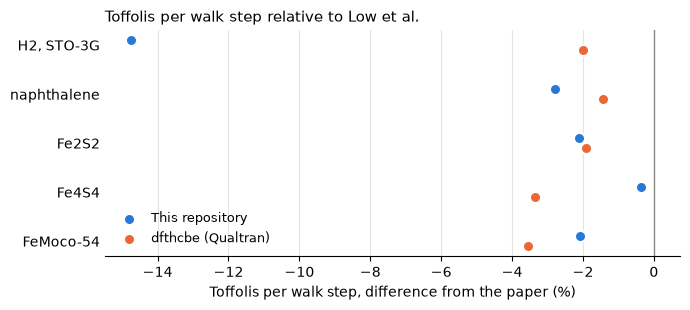

In [6]:
names = [s["label"] for s in systems.values()]
rel = {key: [100 * (s[key] - s["paper"]) / s["paper"] for s in systems.values()]
       for key in ("ours", "dfthcbe")}
y = np.arange(len(names))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvline(0, color="#8a8984", lw=1)
for key, label, color, dy in (("ours", "This repository", "#2a78d6", -0.1),
                              ("dfthcbe", "dfthcbe (Qualtran)", "#eb6834", 0.1)):
    ax.scatter(rel[key], y + dy, s=64, color=color, label=label, zorder=3,
               edgecolor="white", linewidth=1.5)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Toffolis per walk step, difference from the paper (%)")
ax.set_title("Toffolis per walk step relative to Low et al.", loc="left", fontsize=11)
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## 4. Compile and count

Each walk is now compiled to the gate set and counted exactly with `qp.analyze`
(`dfthc.compile.compiled_resources` wraps the qjit/decompose/analyze stack of Section 1). The measured
Toffoli count must equal the closed form of Section 3. By default the small systems compile (H$_2$
and naphthalene, about 10 s each); set `COMPILE_LARGE = True` above for the rest.

In [7]:
def walk_program(s):
    p, t, layout = s["params"], s["tables"], s["layout"]
    def qfunc():
        qp.PhaseGradientStatePrep(layout.phase_grad)
        DFTHCWalk(p.as_compilable(), t.as_compilable(), **layout.groups())
    return qfunc, layout.num_wires

rows = []
for name, s in systems.items():
    if name in LARGE and not COMPILE_LARGE:
        rows.append([s["label"], "—", s["ours"], "skipped", "—", "—", "—"])
        continue
    start = time.perf_counter()
    r = compiled_resources(*walk_program(s))
    seconds = time.perf_counter() - start
    assert r.toffoli == s["ours"], (name, r.toffoli, s["ours"])
    assert r.num_wires == s["layout"].num_wires
    s["compiled"] = r
    rows.append([s["label"], r.toffoli, s["ours"], "equal", r.measured_and_uncomputes,
                 r.measurements, f"{seconds:.0f} s"])

table(["System", "Toffolis compiled", "Closed form", "Check", "Measured AND uncomputes",
       "Mid-circuit measurements", "Compile"], rows)

| System | Toffolis compiled | Closed form | Check | Measured AND uncomputes | Mid-circuit measurements | Compile |
|---|---|---|---|---|---|---|
| H2, STO-3G | 341 | 341 | equal | 341 | 91 | 4 s |
| naphthalene | 1,910 | 1,910 | equal | 1,910 | 484 | 7 s |
| Fe2S2 | — | 4,411 | skipped | — | — | — |
| Fe4S4 | — | 6,533 | skipped | — | — | — |
| FeMoco-54 | — | 9,790 | skipped | — | — | — |

## 5. FeMoco-54, block by block (the paper's Table III)

Toffolis per walk step for each block of the walk, times the number of calls per step. The paper's
Table III charges the tail-angle fix-up ($N = 54$ Toffolis per call) to the inner unprepare, while
dfthcbe and this repository apply it in the angle erase (step 18); the totals are unaffected.

In [8]:
p = FEMOCO54
paper, ref = costs_reference.paper_table3(p), costs_reference.dfthcbe_blocks(p)
BLOCKS = [  # (row, paper steps, calls per walk, our closed form, reference key)
    ("Outer prepare", "1-4", 1, costs.outer_prepare(p), "outer_prepare"),
    ("Inner prepare", "5-8", 2, costs.inner_prepare(p), "inner_prepare"),
    ("Inner signs", "9", 2, costs.inner_signs(), "inner_signs"),
    ("Tail angle load", "10", 2, costs.tail_angle_load(p), "tail_angle_load"),
    ("SF angle load", "11", 2, costs.sf_angle_load(p), "sf_angle_load"),
    ("Spin multiplexer", "12, 17", 4, costs.spin_mux(), "spin_mux"),
    ("Spin swap", "13, 17", 4, costs.spin_swap(p), "spin_swap"),
    ("Givens ladder", "14", 2, costs.givens_ladder(p), "givens_ladder"),
    ("Majorana gate", "15", 1, costs.majorana_gate(), "majorana_gate"),
    ("Majorana gate (adjoint)", "15", 1, costs.majorana_gate(), "majorana_gate_adjoint"),
    ("Givens ladder (adjoint)", "16", 2, costs.givens_ladder(p), "givens_ladder_dagger"),
    ("Angle erase", "18", 2, costs.angle_erase(p), "angle_erase"),
    ("Inner unprepare", "19-22", 2, costs.inner_unprepare_from_outcomes(p), "inner_unprepare"),
    ("REF_T2", "23", 1, costs.ref_t2(p, False), "ref_t2"),
    ("Outer unprepare", "24-27", 1, costs.outer_unprepare_from_outcomes(p), "outer_unprepare"),
    ("REF_A∪B", "28", 1, costs.ref_ab(p, False), "ref_ab"),
]
rows, totals = [], np.zeros(3, dtype=int)
for label, steps, calls, cost, key in BLOCKS:
    values = np.array([calls * cost.toffoli, calls * ref[key], calls * paper[key]])
    totals += values
    rows.append([label, steps, calls, *map(int, values), f"{int(values[0] - values[2]):+,}"])
rows.append(["**Walk**", "1-28", 1, *[f"**{int(v):,}**" for v in totals],
             f"**{int(totals[0] - totals[2]):+,}**"])
table(["Block", "Steps", "Calls", "Ours", "dfthcbe", "Paper", "Ours − paper"], rows)

# The blocks add up to the walk in all three columns.
assert list(totals) == [costs.walk(p, False).toffoli, ref["walk"], paper["walk"]] == [9790, 9641, 9997]

| Block | Steps | Calls | Ours | dfthcbe | Paper | Ours − paper |
|---|---|---|---|---|---|---|
| Outer prepare | 1-4 | 1 | 209 | 212 | 213 | -4 |
| Inner prepare | 5-8 | 2 | 1,940 | 1,826 | 1,760 | +180 |
| Inner signs | 9 | 2 | 0 | 0 | 0 | +0 |
| Tail angle load | 10 | 2 | 122 | 112 | 108 | +14 |
| SF angle load | 11 | 2 | 582 | 542 | 540 | +42 |
| Spin multiplexer | 12, 17 | 4 | 4 | 8 | 0 | +4 |
| Spin swap | 13, 17 | 4 | 216 | 216 | 216 | +0 |
| Givens ladder | 14 | 2 | 2,968 | 2,968 | 3,180 | -212 |
| Majorana gate | 15 | 1 | 5 | 5 | 7 | -2 |
| Majorana gate (adjoint) | 15 | 1 | 5 | 5 | 7 | -2 |
| Givens ladder (adjoint) | 16 | 2 | 2,968 | 2,968 | 3,180 | -212 |
| Angle erase | 18 | 2 | 204 | 180 | 74 | +130 |
| Inner unprepare | 19-22 | 2 | 434 | 440 | 548 | -114 |
| REF_T2 | 23 | 1 | 20 | 20 | 21 | -1 |
| Outer unprepare | 24-27 | 1 | 69 | 94 | 97 | -28 |
| REF_A∪B | 28 | 1 | 44 | 45 | 46 | -2 |
| **Walk** | 1-28 | 1 | **9,790** | **9,641** | **9,997** | **-207** |

Most of the gap to the paper comes from the Givens ladders: each $R_z$ rotation is an add-or-subtract
into the phase gradient costing $b_\mathrm{rot} - 1$ Toffolis, as in dfthcbe, where the paper counts
$b_\mathrm{rot}$ (`rz-addsub`, −424 per step). Against that, the inner prepares and the angle loads
cost more, mostly because unary iteration here is exact rather than truncated and the inner entry
carries both sign bits; `costs_reference.delta_causes(FEMOCO54)` lists every cause with its
contribution.

## 6. Logical qubits at FeMoco-54

The paper's Table 3 lists 1,131 logical qubits. Here they are grouped by the registers of our
`WalkLayout`.

In [9]:
layout = systems["femoco54"]["layout"]
ours = {name: len(w) for name, w in layout.groups().items()}
theirs = costs_reference.PAPER_QUBIT_GROUPS_FEMOCO
rows = [[f"`{g}`", ours[g], theirs[g], f"{ours[g] - theirs[g]:+,}"] for g in theirs]
rows.append(["**total**", layout.num_wires, costs_reference.PAPER_QUBITS_FEMOCO,
             f"{layout.num_wires - costs_reference.PAPER_QUBITS_FEMOCO:+,}"])
table(["Group", "Ours", "Paper", "Ours − paper"], rows)
assert sum(theirs.values()) == costs_reference.PAPER_QUBITS_FEMOCO == 1131

| Group | Ours | Paper | Ours − paper |
|---|---|---|---|
| `system` | 108 | 108 | +0 |
| `outer` | 71 | 50 | +21 |
| `inner` | 65 | 53 | +12 |
| `select` | 746 | 795 | -49 |
| `phase_grad` | 15 | 15 | +0 |
| `work` | 44 | 110 | -66 |
| **total** | 1,049 | 1,131 | -82 |

The saving is in the `select` and `work` groups: both read registers' junk is measured out right
after each prepare, so it can share the rotation-angle register, and the angle registers drop the
paper's always-zero top bit.

## 7. Phase estimation

Iterative QPE with $t$ bits applies the controlled walk $2^t - 1$ times, plus $(t^3 - t)/6$ Toffolis
of phase corrections in the worst case (`costs.iterative_qpe`). Small cases are compiled in the test
suite (`tests/integration/test_qpe_counts.py`); here are the closed forms at FeMoco-54.

In [10]:
from dfthc.qpe import ControlledWalkPower, spare_wires_needed

p, layout = FEMOCO54, systems["femoco54"]["layout"]
sizes = tuple(len(getattr(layout, g)) for g in ControlledWalkPower.wire_argnames[1:])
rows = []
for t in (1, 2, 3, 10, 20, 23):
    # The walk, a QPE control and t phase-gradient wires; the 2t - 1 correction wires borrow the
    # walk's 44-wire work pool, and only beyond it (t > 22) need spare wires.
    qubits = (WalkLayout.from_params(p, qpe_bits=t).num_wires
              + spare_wires_needed("ControlledWalkPower", sizes, t))
    rows.append([t, costs.iterative_qpe(p, t).toffoli, qubits])
table(["QPE bits t", "Toffolis", "Qubits"], rows)

| QPE bits t | Toffolis | Qubits |
|---|---|---|
| 1 | 9,792 | 1,051 |
| 2 | 29,377 | 1,052 |
| 3 | 68,548 | 1,053 |
| 10 | 10,017,381 | 1,060 |
| 20 | 10,267,647,730 | 1,070 |
| 23 | 82,141,241,768 | 1,074 |

## 8. Correctness: the block encoding of H$_2$

Counting gates is only meaningful if the circuit is right. For H$_2$/STO-3G (4 spin orbitals, at the
test precisions) we decompose `DFTHCBlockEncoding` to the same gate set, run it on the repository's
sparse simulator for each of the 16 system basis states, and project the ancillas onto $|0\rangle$.
The result must equal $\tilde H_{SA}/\tilde\Lambda - I$, the block the classical tables encode
(`dfthc.data.encoded.encoded_block`). Every erase outcome here is forced to 0; the test suite checks
other outcome schedules, the walk's Chebyshev powers and the controlled walk.

In [11]:
from dfthc.ops.walk import DFTHCBlockEncoding
from dfthc.testing import walk_sim

case = walk_sim.case("sto3g")  # H2_STO3G_TEST with the h2_sto3g_R2_B2_C1 factors
ops = walk_sim.program(case, DFTHCBlockEncoding)
outcomes = walk_sim.schedule("S0", walk_sim.num_measurements(ops))

columns = []
for v in range(16):
    state = walk_sim.input_state(case, walk_sim.basis(case, v))
    out = walk_sim.simulate(case, ops, state, outcomes)
    columns.append(walk_sim.project(case, out)[0])
simulated = np.array(columns).T

expected = case.block()
print(f"{len(ops):,} gates, {walk_sim.num_measurements(ops)} mid-circuit measurements")
print(f"max |simulated - expected| = {np.abs(simulated - expected).max():.1e}")
assert np.allclose(simulated, expected, rtol=0, atol=1e-10)

1,318 gates, 48 mid-circuit measurements
max |simulated - expected| = 4.3e-16


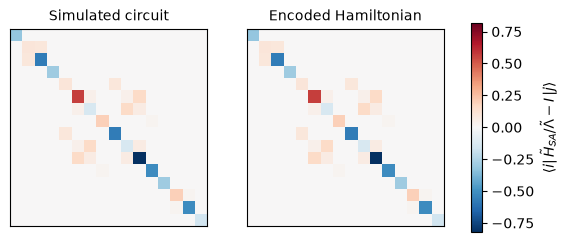

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
for ax, matrix, title in ((axes[0], simulated.real, "Simulated circuit"),
                          (axes[1], expected.real, "Encoded Hamiltonian")):
    lim = np.abs(expected).max()
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$\langle i|\,\tilde H_{SA}/\tilde\Lambda - I\,|j\rangle$")
plt.show()

## Summary

| | Paper | This repository | dfthcbe |
| --- | ---: | ---: | ---: |
| Toffolis per walk step, FeMoco-54 | 9,997 | 9,790 (controlled: 9,792) | 9,641 |
| Logical qubits, FeMoco-54 | 1,131 | 1,049 | — |

Every count above comes from a circuit that compiles to Cliffords, `TemporaryAND` and measurements,
and every compiled count equals its closed form. For the full per-block report of every system,
with Cliffords, measurements and the cause of each difference, see `docs/resources.md`
(regenerated by `scripts/resource_report.py`).